Import Required Libraries

In [ ]:
import os
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG19

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("All Libraries Imported Successfully!")
print("TensorFlow Version:", tf.__version__)

All Libraries Imported Successfully!
TensorFlow Version: 2.21.0


Connect Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


Define Dataset Paths

In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Dataset/Animal"

CATS_DIR = os.path.join(BASE_DIR, "Cats")
DOGS_DIR = os.path.join(BASE_DIR, "Dogs")

CAT_FOLDER = "Cats"
DOG_FOLDER = "Dogs"

print("Cats Directory:", CATS_DIR)
print("Dogs Directory:", DOGS_DIR)

print("Cats Folders:", os.listdir(CATS_DIR))
print("Dogs Folders:", os.listdir(DOGS_DIR))

Cats Directory: /content/drive/MyDrive/Dataset/Animal/Cats
Dogs Directory: /content/drive/MyDrive/Dataset/Animal/Dogs
Cats Folders: ['cat.753.jpg', 'cat.383.jpg', 'cat.372.jpg', 'cat.3715.jpg', 'cat.507.jpg', 'cat.651.jpg', 'cat.388.jpg', 'cat.3779.jpg', 'cat.3721.jpg', 'cat.730.jpg', 'cat.606.jpg', 'cat.658.jpg', 'cat.608.jpg', 'cat.666.jpg', 'cat.73.jpg', 'cat.541.jpg', 'cat.3867.jpg', 'cat.649.jpg', 'cat.3723.jpg', 'cat.635.jpg', 'cat.642.jpg', 'cat.545.jpg', 'cat.483.jpg', 'cat.3853.jpg', 'cat.41.jpg', 'cat.696.jpg', 'cat.3892.jpg', 'cat.3817.jpg', 'cat.650.jpg', 'cat.3845.jpg', 'cat.634.jpg', 'cat.3917.jpg', 'cat.3882.jpg', 'cat.582.jpg', 'cat.3860.jpg', 'cat.690.jpg', 'cat.765.jpg', 'cat.3889.jpg', 'cat.693.jpg', 'cat.722.jpg', 'cat.45.jpg', 'cat.641.jpg', 'cat.3791.jpg', 'cat.71.jpg', 'cat.476.jpg', 'cat.594.jpg', 'cat.49.jpg', 'cat.3987.jpg', 'cat.531.jpg', 'cat.763.jpg', 'cat.3874.jpg', 'cat.3971.jpg', 'cat.515.jpg', 'cat.467.jpg', 'cat.390.jpg', 'cat.716.jpg', 'cat.604.jpg', 

Collect All Image Paths

In [ ]:
image_paths = []
image_labels = []

# Cat = 0
for filename in os.listdir(CATS_DIR):

    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp")
    ):

        image_paths.append(
            os.path.join(CATS_DIR, filename)
        )

        image_labels.append(0)


# Dog = 1
for filename in os.listdir(DOGS_DIR):

    if filename.lower().endswith(
        (".jpg", ".jpeg", ".png", ".bmp")
    ):

        image_paths.append(
            os.path.join(DOGS_DIR, filename)
        )

        image_labels.append(1)


image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total Images:", len(image_paths))
print("Total Cats:", np.sum(image_labels == 0))
print("Total Dogs:", np.sum(image_labels == 1))

Total Images: 10000
Total Cats: 5000
Total Dogs: 5000


Create 70/15/15 Dataset Split

In [ ]:
# First split: 70% training, 30% remaining

X_train, X_remaining, y_train, y_remaining = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# Second split: 15% validation, 15% testing

X_val, X_test, y_val, y_test = train_test_split(
    X_remaining,
    y_remaining,
    test_size=0.50,
    random_state=42,
    stratify=y_remaining
)


print("Training Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

print("\nDataset Split Completed!")

Training Images: 7000
Validation Images: 1500
Testing Images: 1500

Dataset Split Completed!


Display Dataset Split

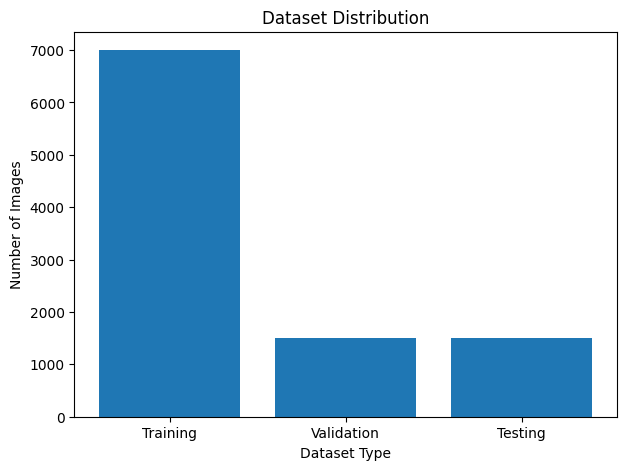

In [ ]:
split_names = [
    "Training",
    "Validation",
    "Testing"
]

split_counts = [
    len(X_train),
    len(X_val),
    len(X_test)
]

plt.figure(figsize=(7, 5))

plt.bar(split_names, split_counts)

plt.title("Dataset Distribution")
plt.xlabel("Dataset Type")
plt.ylabel("Number of Images")

plt.show()

Display Sample Images

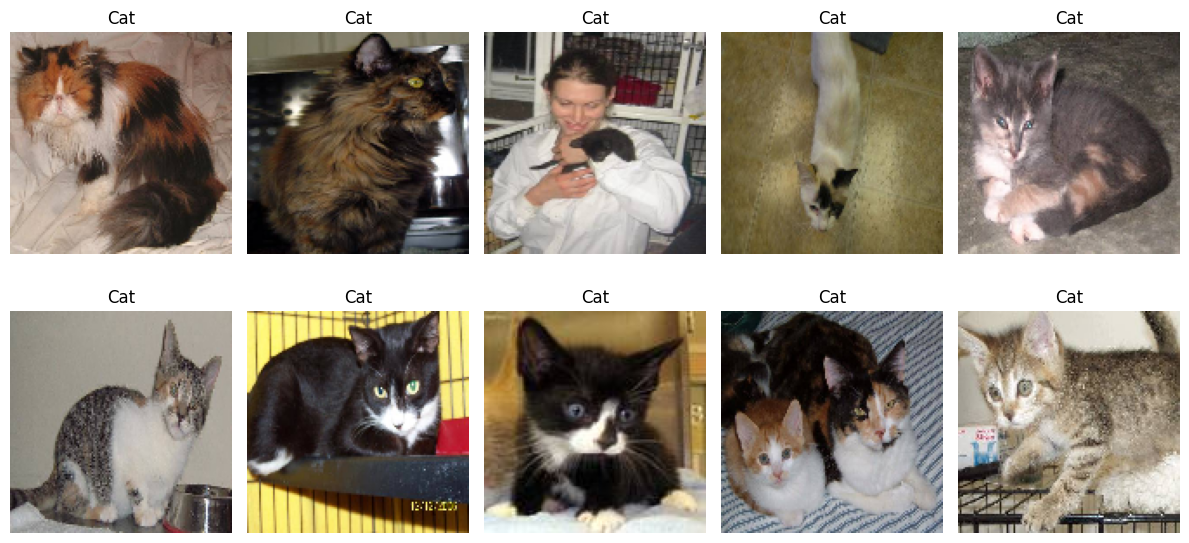

In [ ]:
plt.figure(figsize=(12, 6))

for i in range(10):

    image = tf.keras.utils.load_img(
        image_paths[i],
        target_size=(128, 128)
    )

    plt.subplot(2, 5, i + 1)

    plt.imshow(image)

    label = "Dog" if image_labels[i] == 1 else "Cat"

    plt.title(label)
    plt.axis("off")

plt.tight_layout()
plt.show()

Create TensorFlow Dataset Function

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 16

def create_dataset(paths, labels, image_size, model_type):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(
            image,
            image_size
        )

        image = tf.cast(image, tf.float32)

        if model_type == "vgg19":

            image = tf.keras.applications.vgg19.preprocess_input(
                image
            )

        else:

            image = image / 255.0

        return image, tf.cast(label, tf.float32)

    dataset = dataset.map(
        load_image,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(AUTOTUNE)

    return dataset

Create Custom CNN Datasets

In [ ]:
train_cnn = create_dataset(
    X_train, y_train, (128, 128), "cnn"
)

val_cnn = create_dataset(
    X_val, y_val, (128, 128), "cnn"
)

test_cnn = create_dataset(
    X_test, y_test, (128, 128), "cnn"
)

print("Custom CNN Datasets Created!")

Custom CNN Datasets Created!


Create VGG19 Datasets

In [ ]:
train_vgg = create_dataset(
    X_train, y_train, (224, 224), "vgg19"
)

val_vgg = create_dataset(
    X_val, y_val, (224, 224), "vgg19"
)

test_vgg = create_dataset(
    X_test, y_test, (224, 224), "vgg19"
)

print("VGG19 Datasets Created!")

VGG19 Datasets Created!


Build Custom CNN Model

In [ ]:
def build_custom_cnn():

    model = models.Sequential([

        layers.Input(shape=(128, 128, 3)),

        layers.Conv2D(
            32,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            128,
            (3, 3),
            activation="relu"
        ),

        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),

        layers.Dense(
            128,
            activation="relu"
        ),

        layers.Dense(
            1,
            activation="sigmoid"
        )

    ])

    return model


cnn_model = build_custom_cnn()

cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,769 (12.61 MB)

 Trainable params: 3,304,769 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Compile Custom CNN

In [ ]:
cnn_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("Custom CNN Compiled!")

Custom CNN Compiled!


Train Custom CNN

In [ ]:
start_time = time.time()

cnn_history = cnn_model.fit(

    train_cnn,

    validation_data=val_cnn,

    epochs=20

)

cnn_training_time = time.time() - start_time

print(
    "Custom CNN Training Time:",
    round(cnn_training_time, 2),
    "seconds"
)

Plot Custom CNN Accuracy

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Custom CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

NameError: name 'cnn_history' is not defined

<Figure size 800x500 with 0 Axes>

Plot Custom CNN Loss

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Custom CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Load Pretrained VGG19

In [ ]:
vgg_base = VGG19(

    weights="imagenet",

    include_top=False,

    input_shape=(224, 224, 3)

)

# Freeze pretrained layers

vgg_base.trainable = False

print("VGG19 Pretrained Model Loaded!")

print("Total VGG19 Layers:", len(vgg_base.layers))

Build VGG19 Classification Model

In [ ]:
def build_vgg19():

    inputs = layers.Input(
        shape=(224, 224, 3)
    )

    features = vgg_base(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(features)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.30)(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs
    )

    return model


vgg_model = build_vgg19()

vgg_model.summary()

Compile VGG19 Model

In [ ]:
vgg_model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("VGG19 Model Compiled!")

Train VGG19 Model

In [ ]:
start_time = time.time()

vgg_history = vgg_model.fit(

    train_vgg,

    validation_data=val_vgg,

    epochs=15

)

vgg_training_time = time.time() - start_time

print(
    "VGG19 Training Time:",
    round(vgg_training_time, 2),
    "seconds"
)

Plot VGG19 Accuracy

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    vgg_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    vgg_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("VGG19 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Plot VGG19 Loss

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    vgg_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    vgg_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("VGG19 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Evaluate Custom CNN

In [ ]:

cnn_predictions = cnn_model.predict(
    test_cnn,
    verbose=1
)

cnn_pred_labels = (
    cnn_predictions.flatten() >= 0.5
).astype(int)

cnn_actual_labels = y_test


cnn_accuracy = accuracy_score(
    cnn_actual_labels,
    cnn_pred_labels
)

cnn_precision = precision_score(
    cnn_actual_labels,
    cnn_pred_labels,
    zero_division=0
)

cnn_recall = recall_score(
    cnn_actual_labels,
    cnn_pred_labels,
    zero_division=0
)

cnn_f1 = f1_score(
    cnn_actual_labels,
    cnn_pred_labels,
    zero_division=0
)

print("CUSTOM CNN RESULTS")

print("Accuracy:", round(cnn_accuracy, 4))
print("Precision:", round(cnn_precision, 4))
print("Recall:", round(cnn_recall, 4))
print("F1 Score:", round(cnn_f1, 4))

print("\nClassification Report:")

print(
    classification_report(
        cnn_actual_labels,
        cnn_pred_labels,
        target_names=["Cat", "Dog"],
        zero_division=0
    )
)

Custom CNN Confusion Matrix

In [ ]:
cnn_cm = confusion_matrix(
    cnn_actual_labels,
    cnn_pred_labels,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Blues")

plt.title("Custom CNN Confusion Matrix")

plt.show()

Evaluate VGG19

In [ ]:
# Predict test images

vgg_predictions = vgg_model.predict(
    test_vgg,
    verbose=1
)

# Convert probabilities into labels

vgg_pred_labels = (
    vgg_predictions.flatten() >= 0.5
).astype(int)

# Actual labels

vgg_actual_labels = y_test

# Calculate metrics

vgg_accuracy = accuracy_score(
    vgg_actual_labels,
    vgg_pred_labels
)

vgg_precision = precision_score(
    vgg_actual_labels,
    vgg_pred_labels,
    zero_division=0
)

vgg_recall = recall_score(
    vgg_actual_labels,
    vgg_pred_labels,
    zero_division=0
)

vgg_f1 = f1_score(
    vgg_actual_labels,
    vgg_pred_labels,
    zero_division=0
)

print("VGG19 RESULTS")

print("Accuracy:", round(vgg_accuracy, 4))
print("Precision:", round(vgg_precision, 4))
print("Recall:", round(vgg_recall, 4))
print("F1 Score:", round(vgg_f1, 4))

print("\nClassification Report:")

print(
    classification_report(
        vgg_actual_labels,
        vgg_pred_labels,
        target_names=["Cat", "Dog"],
        zero_division=0
    )
)

VGG19 Confusion Matrix

In [ ]:
vgg_cm = confusion_matrix(
    vgg_actual_labels,
    vgg_pred_labels,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=vgg_cm,
    display_labels=["Cat", "Dog"]
)

disp.plot(cmap="Greens")

plt.title("VGG19 Confusion Matrix")

plt.show()

Calculate Trainable Parameters

In [ ]:
cnn_trainable_params = sum(
    np.prod(weight.shape)
    for weight in cnn_model.trainable_weights
)

vgg_trainable_params = sum(
    np.prod(weight.shape)
    for weight in vgg_model.trainable_weights
)

print("Custom CNN Trainable Parameters:",
      f"{cnn_trainable_params:,}")

print("VGG19 Trainable Parameters:",
      f"{vgg_trainable_params:,}")

Create Final Comparison Table

In [ ]:
results = {

    "Metric": [
        "Test Accuracy (%)",
        "Precision",
        "Recall",
        "F1 Score",
        "Training Time (Seconds)",
        "Trainable Parameters"
    ],

    "Custom CNN": [

        cnn_accuracy * 100,

        cnn_precision,

        cnn_recall,

        cnn_f1,

        cnn_training_time,

        cnn_trainable_params
    ],

    "VGG19": [

        vgg_accuracy * 100,

        vgg_precision,

        vgg_recall,

        vgg_f1,

        vgg_training_time,

        vgg_trainable_params
    ]

}

comparison_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")

display(comparison_df.round(4))

Compare Test Accuracy

In [ ]:
accuracy_values = [
    cnn_accuracy * 100,
    vgg_accuracy * 100
]

model_names = [
    "Custom CNN",
    "VGG19"
]

plt.figure(figsize=(7, 5))

plt.bar(
    model_names,
    accuracy_values
)

plt.title("Test Accuracy Comparison")

plt.xlabel("Models")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 100)

for i, value in enumerate(accuracy_values):

    plt.text(
        i,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.show()

Determine the Better Model

In [ ]:
if vgg_accuracy > cnn_accuracy:

    print("VGG19 achieved higher test accuracy.")

elif cnn_accuracy > vgg_accuracy:

    print("Custom CNN achieved higher test accuracy.")

else:

    print("Both models achieved equal test accuracy.")


print("\nCustom CNN Accuracy:",
      f"{cnn_accuracy * 100:.2f}%")

print("VGG19 Accuracy:",
      f"{vgg_accuracy * 100:.2f}%")

Compare Training and Validation Accuracy

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    cnn_history.history["accuracy"],
    label="CNN Training"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="CNN Validation"
)

plt.plot(
    vgg_history.history["accuracy"],
    label="VGG19 Training"
)

plt.plot(
    vgg_history.history["val_accuracy"],
    label="VGG19 Validation"
)

plt.title("CNN vs VGG19 Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

Compare Training and Validation Loss

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    cnn_history.history["loss"],
    label="CNN Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="CNN Validation Loss"
)

plt.plot(
    vgg_history.history["loss"],
    label="VGG19 Training Loss"
)

plt.plot(
    vgg_history.history["val_loss"],
    label="VGG19 Validation Loss"
)

plt.title("CNN vs VGG19 Loss Comparison")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
cnn_model.save(
    "/content/custom_cnn_model.keras"
)

vgg_model.save(
    "/content/vgg19_model.keras"
)

print("Both Models Saved Successfully!")

Save Both Trained Models

In [ ]:
comparison_df.to_csv(
    "/content/model_comparison.csv",
    index=False
)

comparison_df.to_excel(
    "/content/model_comparison.xlsx",
    index=False
)

print("Comparison Files Saved!")

Export Comparison Results

In [ ]:
from google.colab import files

files.download(
    "/content/model_comparison.csv"
)